# Assignment 6

## Aim:
To smooth the input image using:
1. Averaging Filter (Un-weighted)
2. Weighted Filter
3. Gaussian Filter

Libraries Used: OpenCV, NumPy and Matplotlib.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()

image_name = list(uploaded.keys())[0]

img = cv2.imread(image_name)

if img is None:
    print("Image not loaded")
else:
    print("Image loaded successfully")

Saving newimage.jpeg to newimage.jpeg
Image loaded successfully


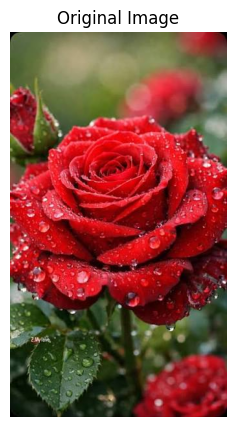

In [3]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 5))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
filter_size = int(input("Enter filter size: "))
sigma = float(input("Enter Gaussian sigma: "))

print("1. Zero Padding")
print("2. Replication Padding")

choice = int(input("Choose padding method: "))

if filter_size < 3 or filter_size % 2 == 0:
    raise ValueError("Enter an odd filter size greater than or equal to 3")

if sigma <= 0:
    raise ValueError("Sigma must be greater than 0")

if choice == 1:
    padding_type = cv2.BORDER_CONSTANT
elif choice == 2:
    padding_type = cv2.BORDER_REPLICATE
else:
    raise ValueError("Invalid padding choice")

Enter filter size: 3
Enter Gaussian sigma: 1
1. Zero Padding
2. Replication Padding
Choose padding method: 2


In [5]:
pad = filter_size // 2

padded_img = cv2.copyMakeBorder(
    img,
    pad, pad, pad, pad,
    padding_type
)

print("Padding applied successfully")

Padding applied successfully


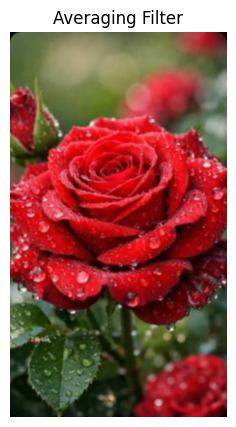

In [6]:
average_kernel = np.ones(
    (filter_size, filter_size),
    dtype=np.float32
)

average_kernel = average_kernel / (filter_size * filter_size)

average_result = cv2.filter2D(
    padded_img, -1, average_kernel
)

average_result = average_result[pad:-pad, pad:-pad]

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(average_result, cv2.COLOR_BGR2RGB))
plt.title("Averaging Filter")
plt.axis("off")
plt.show()

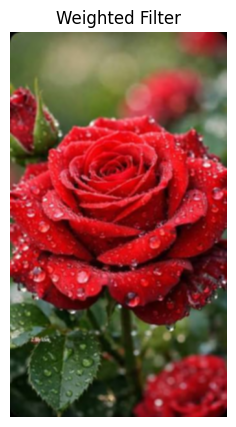

In [7]:
x, y = np.meshgrid(
    np.arange(-pad, pad + 1),
    np.arange(-pad, pad + 1)
)

weighted_kernel = np.maximum(
    np.abs(x), np.abs(y)
).astype(np.float32)

weighted_kernel = weighted_kernel / np.sum(weighted_kernel)

weighted_result = cv2.filter2D(
    padded_img, -1, weighted_kernel
)

weighted_result = weighted_result[pad:-pad, pad:-pad]

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(weighted_result, cv2.COLOR_BGR2RGB))
plt.title("Weighted Filter")
plt.axis("off")
plt.show()

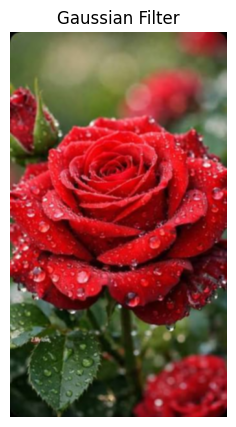

In [8]:
gaussian_1d = cv2.getGaussianKernel(filter_size, sigma)

gaussian_kernel = gaussian_1d @ gaussian_1d.T

gaussian_result = cv2.filter2D(
    padded_img, -1, gaussian_kernel
)

gaussian_result = gaussian_result[pad:-pad, pad:-pad]

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(gaussian_result, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter")
plt.axis("off")
plt.show()

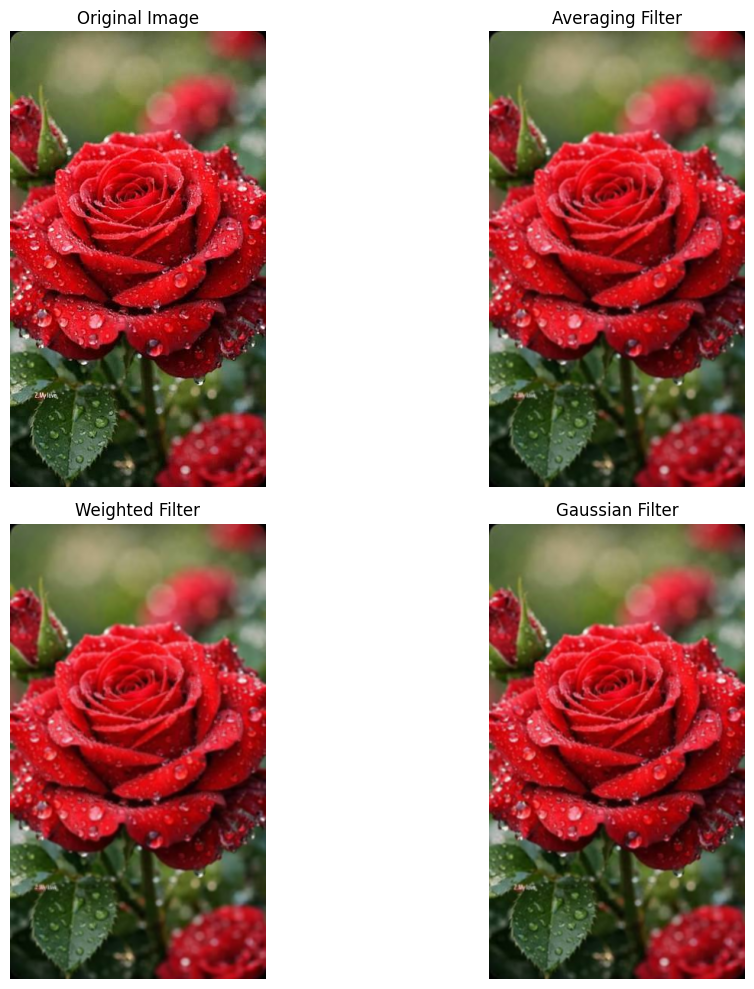

In [9]:
images = [
    img,
    average_result,
    weighted_result,
    gaussian_result
]

titles = [
    "Original Image",
    "Averaging Filter",
    "Weighted Filter",
    "Gaussian Filter"
]

plt.figure(figsize=(12, 10))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    display_image = cv2.cvtColor(
        images[i], cv2.COLOR_BGR2RGB
    )

    plt.imshow(display_image)
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Result:

The input image was successfully smoothed using three different filters:

1. Averaging Filter (Un-weighted)
2. Weighted Filter
3. Gaussian Filter

The effects of different filter sizes, sigma values and padding methods were observed.
